# Analisis & Persiapan Data Gizi Makanan Indonesia (UTS)

Notebook ini melanjutkan kode awal (library, load data, missing value, statistik deskriptif, histogram kalori, heatmap korelasi) dan melengkapinya sesuai **Daftar Capaian progres presentasi**:

| Bagian | Capaian (No) |
|---|---|
| A. Data Understanding | 1 – 5 |
| B. EDA | 6 – 8 |
| C. Audit Kualitas Data | 9 |
| D. Cleaning | 10 – 11 |
| E. Preprocessing | 12 – 13 |
| F. Feature Selection | 14 |

**Tujuan analisis:** memprediksi **kategori kalori** makanan (*Rendah / Sedang / Tinggi*) dari kandungan gizi dan informasi nama makanan.

## Library

In [1]:
# Mengimpor library yang dibutuhkan untuk pengolahan data dan visualisasi
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.utils import resample
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Dataset

In [2]:
# Membaca dataset CSV
df = pd.read_csv('nutrition.csv')

# Menampilkan 5 baris pertama data
display(df.head())
print("Ukuran data (baris, kolom):", df.shape)

,id,calories,proteins,fat,carbohydrate,name,image
0,1,280.0,9.2,28.4,0.0,Abon,https://img-cdn.medkomtek.com/PbrY9X3ignQ8sVuj...
1,2,513.0,23.7,37.0,21.3,Abon haruwan,https://img-global.cpcdn.com/recipes/cbf330fbd...
2,3,0.0,0.0,0.2,0.0,Agar-agar,https://res.cloudinary.com/dk0z4ums3/image/upl...
3,4,45.0,1.1,0.4,10.8,Akar tonjong segar,https://images.tokopedia.net/img/cache/200-squ...
4,5,37.0,4.4,0.5,3.8,Aletoge segar,https://nilaigizi.com/assets/images/produk/pro...


Ukuran data (baris, kolom): (1346, 7)


# A. Data Understanding

## 1. Sumber Data & Lisensi / Izin

| Item | Keterangan |
|---|---|
| Nama dataset | *Indonesian Food and Drink Nutrition Dataset* (file `nutrition.csv`) |
| Isi | Informasi gizi makanan & minuman Indonesia: kalori, protein, lemak, karbohidrat, nama, dan URL gambar |
| Sumber nilai gizi | Data nilai gizi pangan Indonesia (mengacu pada acuan seperti TKPI Kemenkes dan situs gizi) |
| Cara akses | Diunduh dari Kaggle dalam format CSV |
| Lisensi / izin | **[ISI: cek lisensi pada halaman dataset Kaggle sebelum presentasi]** |
| Penggunaan | Hanya untuk keperluan akademik (tugas UTS), tidak dikomersialkan |

> Catatan: kolom `image` hanya berisi tautan ke situs pihak lain. Gambar tidak diunduh dan tidak dipakai dalam analisis.

## 2. Data Dictionary (variabel, tipe, unit)

Unit **per 100 gram** adalah asumsi, karena dataset tidak mencantumkannya. Asumsi ini didukung bukti di bawah: untuk hampir semua baris, jumlah protein + lemak + karbohidrat tidak melebihi 100 g.

In [3]:
data_dictionary = pd.DataFrame({
    'Variabel': ['id', 'calories', 'proteins', 'fat', 'carbohydrate', 'name', 'image'],
    'Tipe (di pandas)': [str(df[c].dtype) for c in ['id', 'calories', 'proteins', 'fat', 'carbohydrate', 'name', 'image']],
    'Jenis': ['Identifier', 'Numerik kontinu', 'Numerik kontinu', 'Numerik kontinu', 'Numerik kontinu', 'Teks (nama makanan)', 'Teks (URL)'],
    'Unit': ['-', 'kkal', 'gram', 'gram', 'gram', '-', '-'],
    'Deskripsi': ['Nomor urut unik tiap makanan',
                  'Energi makanan',
                  'Kandungan protein',
                  'Kandungan lemak',
                  'Kandungan karbohidrat',
                  'Nama makanan / minuman',
                  'Tautan gambar makanan (tidak dianalisis)'],
    'Contoh': [df['id'].iloc[0], df['calories'].iloc[0], df['proteins'].iloc[0], df['fat'].iloc[0],
               df['carbohydrate'].iloc[0], df['name'].iloc[0], str(df['image'].iloc[0])[:35] + '...']
})
display(data_dictionary)

# Bukti asumsi "per 100 gram": berapa baris dengan protein + lemak + karbohidrat <= 100 g?
total_makro = df['proteins'] + df['fat'] + df['carbohydrate']
print(f"Baris dengan total makro <= 100 g: {(total_makro <= 100).sum()} dari {len(df)} "
      f"({(total_makro <= 100).mean()*100:.1f}%)")

,Variabel,Tipe (di pandas),Jenis,Unit,Deskripsi,Contoh
0,id,int64,Identifier,-,Nomor urut unik tiap makanan,1
1,calories,float64,Numerik kontinu,kkal,Energi makanan,280.0
2,proteins,float64,Numerik kontinu,gram,Kandungan protein,9.2
3,fat,float64,Numerik kontinu,gram,Kandungan lemak,28.4
4,carbohydrate,float64,Numerik kontinu,gram,Kandungan karbohidrat,0.0
5,name,str,Teks (nama makanan),-,Nama makanan / minuman,Abon
6,image,str,Teks (URL),-,Tautan gambar makanan (tidak dianalisis),https://img-cdn.medkomtek.com/PbrY9...


Baris dengan total makro <= 100 g: 1335 dari 1346 (99.2%)


## 3. Kualitas Data (missing, outlier, duplikasi)

In [4]:
# Melihat struktur dataset (jumlah baris, kolom, dan tipe data)
print("--- Informasi Dataset ---")
df.info()

# Mengecek nilai kosong (missing values)
print("\n--- Pengecekan Missing Value ---")
print(df.isnull().sum())

# Mengecek data yang duplikat
print(f"\n--- Jumlah Baris Duplikat (seluruh kolom) ---")
print(df.duplicated().sum())

--- Informasi Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 1346 entries, 0 to 1345
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            1346 non-null   int64  
 1   calories      1346 non-null   float64
 2   proteins      1346 non-null   float64
 3   fat           1346 non-null   float64
 4   carbohydrate  1346 non-null   float64
 5   name          1346 non-null   str    
 6   image         1346 non-null   str    
dtypes: float64(4), int64(1), str(2)
memory usage: 233.5 KB

--- Pengecekan Missing Value ---
id              0
calories        0
proteins        0
fat             0
carbohydrate    0
name            0
image           0
dtype: int64

--- Jumlah Baris Duplikat (seluruh kolom) ---
0


In [5]:
# Pengecekan kualitas yang lebih dalam (di luar cek bawaan)
nama_norm = df['name'].str.strip().str.lower()
print("Nama dengan spasi di awal/akhir        :", (df['name'] != df['name'].str.strip()).sum())
print("Nama duplikat (abaikan huruf besar/kecil):", nama_norm.duplicated().sum())
print("URL gambar yang dipakai berulang        :", df['image'].duplicated().sum())

print("\nNilai nol per kolom gizi:")
print((df[['calories', 'proteins', 'fat', 'carbohydrate']] == 0).sum())

# Kewajaran nilai: jika unit per 100 g, total makro tidak boleh melebihi 100 g
print("\nBaris dengan protein+lemak+karbohidrat > 100 g (tidak wajar):", (total_makro > 100).sum())

# Konsistensi energi: kalori seharusnya mendekati 4*protein + 9*lemak + 4*karbohidrat
energi_estimasi = 4 * df['proteins'] + 9 * df['fat'] + 4 * df['carbohydrate']
selisih_rel = (energi_estimasi - df['calories']).abs() / energi_estimasi.clip(lower=1)
selisih_abs = (energi_estimasi - df['calories']).abs()
tdk_konsisten = (selisih_rel > 0.5) & (selisih_abs > 20)
print("Baris dengan kalori sangat tidak konsisten dengan makro (selisih >50% dan >20 kkal):", tdk_konsisten.sum())
display(df[tdk_konsisten].assign(energi_estimasi=energi_estimasi[tdk_konsisten].round(1))
        [['name', 'calories', 'proteins', 'fat', 'carbohydrate', 'energi_estimasi']].head(8))

Nama dengan spasi di awal/akhir        : 83
Nama duplikat (abaikan huruf besar/kecil): 3
URL gambar yang dipakai berulang        : 39

Nilai nol per kolom gizi:
calories          1
proteins         22
fat              26
carbohydrate    104
dtype: int64

Baris dengan protein+lemak+karbohidrat > 100 g (tidak wajar): 11
Baris dengan kalori sangat tidak konsisten dengan makro (selisih >50% dan >20 kkal): 30


,name,calories,proteins,fat,carbohydrate,energi_estimasi
53,Babi hutan masak rica masakan,491.0,24.6,16.3,0.2,245.9
77,Bawang Merah,39.0,1.5,0.3,0.2,9.5
132,Beras Siger,344.0,1.1,0.2,28.3,119.4
146,Bir (4% alkohol),48.0,0.6,0.0,4.4,20.0
174,Bubur,60.0,1.0,60.0,13.0,596.0
176,Bubur tinotuan (Manado),156.0,2.3,0.2,15.6,73.4
204,Cassavastick,460.0,0.8,18.7,17.2,240.3
267,Daun Labu Siam,60.0,4.0,0.4,4.7,38.4


**Temuan kualitas data**
- Tidak ada *missing value* dan tidak ada baris yang duplikat penuh.
- Ada duplikasi tersembunyi: nama sama yang berbeda penulisan huruf besar/kecil, dan banyak nama dengan spasi berlebih.
- Ada nilai **tidak masuk akal**: total protein+lemak+karbohidrat melebihi 100 g (misalnya karbohidrat 647 g pada *Pilus*) dan kalori yang sangat jauh dari hitungan makro (misalnya *Pisang Siam goreng*).
- Nilai nol pada protein/lemak/karbohidrat **wajar** (mis. minyak tidak punya karbohidrat), jadi tidak dianggap missing.
- Outlier dihitung per kolom pada bagian **Audit (No. 9)**.

## 4. EDA Berinsight (distribusi / korelasi)

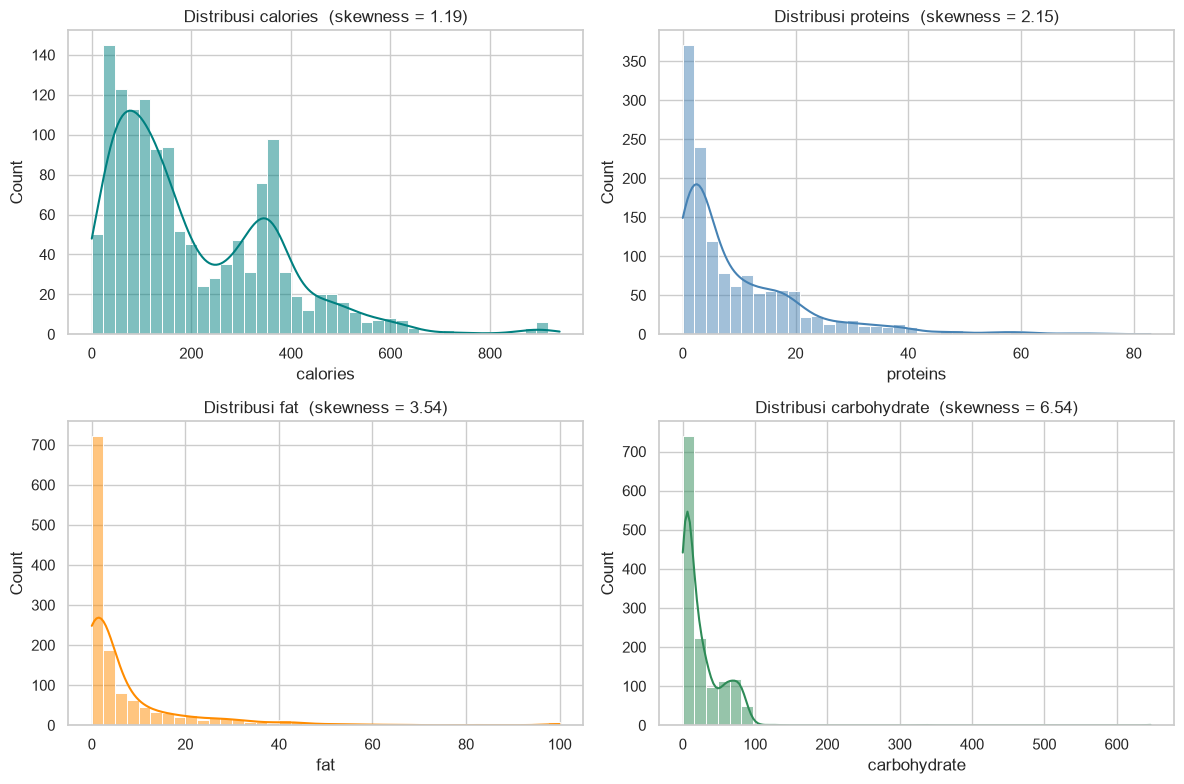

In [6]:
# Distribusi keempat variabel numerik
kolom_numerik = ['calories', 'proteins', 'fat', 'carbohydrate']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
warna = ['teal', 'steelblue', 'darkorange', 'seagreen']
for ax, kol, w in zip(axes.ravel(), kolom_numerik, warna):
    sns.histplot(df[kol], bins=40, kde=True, color=w, ax=ax)
    ax.set_title(f'Distribusi {kol}  (skewness = {df[kol].skew():.2f})')
plt.tight_layout()
plt.show()

**Insight distribusi & korelasi**
1. Semua variabel gizi **condong ke kanan** (*right-skewed*, skewness positif): sebagian besar makanan bernilai gizi rendah, hanya sedikit yang sangat tinggi (minyak, gorengan, kacang). Model sensitif outlier perlu penskalaan yang tahan outlier.
2. Banyak makanan bernilai 0 pada lemak/protein, sehingga ada penumpukan di sekitar nol.
3. Dari heatmap korelasi (bagian EDA No. 8), **lemak** paling kuat berhubungan dengan kalori, diikuti karbohidrat dan protein. Hal ini sesuai teori: lemak 9 kkal/g, protein dan karbohidrat 4 kkal/g.

## 5. Representativitas & Bias Sampel

Dataset tidak punya kolom kategori makanan, jadi kategori **diturunkan dari kata kunci pada nama makanan**. Fungsi ini juga dipakai ulang untuk pembuatan fitur baru pada bagian Feature Selection.

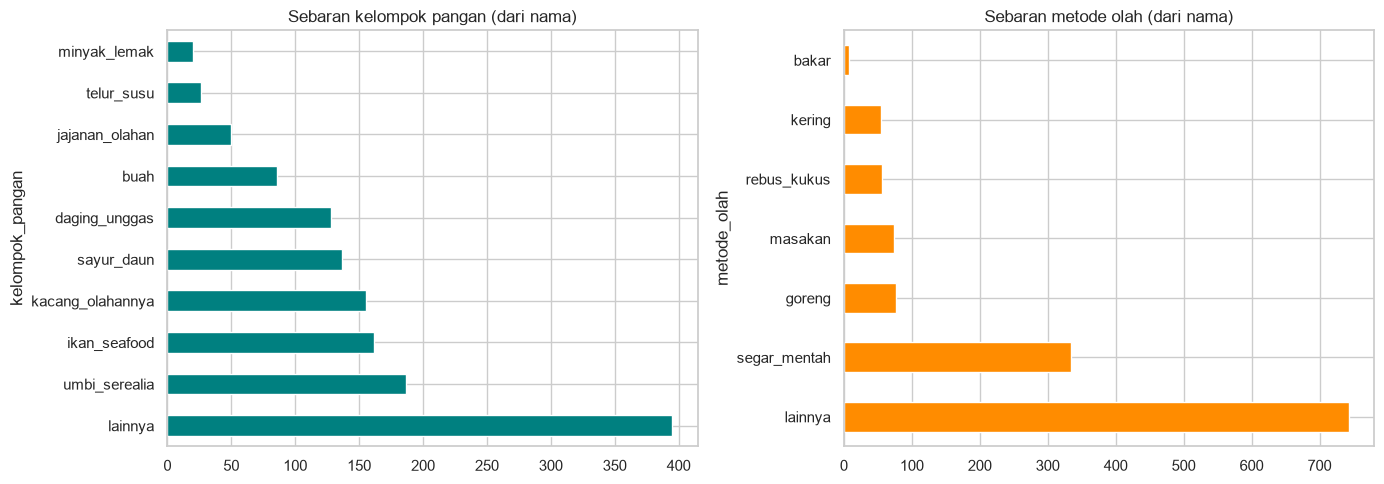

Jumlah situs sumber gambar berbeda: 330
Lima sumber gambar terbanyak:
sumber_gambar
images.tokopedia.net      116
asset.kompas.com          114
img-global.cpcdn.com      107
awsimages.detik.net.id     44
asset-a.grid.id            40
Name: count, dtype: int64

Porsi nama bermetode 'segar/mentah': 24.8%
Porsi kelompok 'lainnya' (tak teridentifikasi): 29.3%


In [7]:
# Fungsi untuk menurunkan metode olah & kelompok pangan dari nama makanan
def metode_olah(nama):
    n = str(nama).lower()
    if 'goreng' in n: return 'goreng'
    if 'rebus' in n or 'kukus' in n: return 'rebus_kukus'
    if 'bakar' in n or 'panggang' in n: return 'bakar'
    if 'masakan' in n or 'masak ' in n: return 'masakan'
    if 'kering' in n: return 'kering'
    if 'segar' in n or 'mentah' in n: return 'segar_mentah'
    return 'lainnya'

KATA_KUNCI = {
    'minyak_lemak'   : ['minyak', 'lemak', 'mentega', 'margarin'],
    'ikan_seafood'   : ['ikan', 'udang', 'kerang', 'cumi', 'kepiting', 'tiram', 'lokan', 'teri', 'rebon', 'belut'],
    'daging_unggas'  : ['daging', 'ayam', 'sapi', 'kambing', 'babi', 'bebek', 'itik', 'usus', 'babat', 'hati', 'dendeng', 'sosis', 'abon', 'rusa'],
    'telur_susu'     : ['telur', 'susu', 'keju', 'yoghurt'],
    'kacang_olahannya': ['kacang', 'kedelai', 'tempe', 'tahu', 'koro', 'biji', 'oncom'],
    'sayur_daun'     : ['daun', 'sayur', 'kangkung', 'bayam', 'bunga', 'kol', 'terong', 'tauge', 'sawi', 'labu', 'kecipir', 'buncis'],
    'buah'           : ['buah', 'jeruk', 'pisang', 'mangga', 'apel', 'salak', 'sirsak', 'pepaya', 'nanas', 'semangka', 'durian', 'jambu', 'rambutan', 'markisa', 'alpukat', 'anggur', 'melon', 'duku', 'nangka'],
    'umbi_serealia'  : ['ubi', 'singkong', 'talas', 'kentang', 'garut', 'gembili', 'sagu', 'beras', 'nasi', 'jagung', 'gandum', 'mi ', 'mie', 'roti', 'tepung', 'bihun', 'oyek', 'tiwul', 'ketan'],
    'jajanan_olahan' : ['kue', 'kerupuk', 'keripik', 'bika', 'dodol', 'wajik', 'biskuit', 'cake', 'opak', 'pilus', 'bubur', 'bakso', 'lemper', 'onde'],
}
def kelompok_pangan(nama):
    n = str(nama).lower()
    for kel, kata in KATA_KUNCI.items():
        if any(k in n for k in kata):
            return kel
    return 'lainnya'

tmp = pd.DataFrame({'metode_olah': df['name'].map(metode_olah),
                    'kelompok_pangan': df['name'].map(kelompok_pangan),
                    'sumber_gambar': df['image'].str.extract(r'https?://([^/]+)')[0]})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tmp['kelompok_pangan'].value_counts().plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Sebaran kelompok pangan (dari nama)')
tmp['metode_olah'].value_counts().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Sebaran metode olah (dari nama)')
plt.tight_layout()
plt.show()

print("Jumlah situs sumber gambar berbeda:", tmp['sumber_gambar'].nunique())
print("Lima sumber gambar terbanyak:")
print(tmp['sumber_gambar'].value_counts().head(5))
print(f"\nPorsi nama bermetode 'segar/mentah': {(tmp['metode_olah']=='segar_mentah').mean()*100:.1f}%")
print(f"Porsi kelompok 'lainnya' (tak teridentifikasi): {(tmp['kelompok_pangan']=='lainnya').mean()*100:.1f}%")

**Penilaian representativitas & bias**
- **Cakupan geografis:** data hanya memuat pangan Indonesia, sehingga model **tidak layak digeneralisasi** ke makanan negara lain.
- **Bias jenis pangan:** entri didominasi **bahan pangan dasar** (ikan, kacang, umbi/serealia, sayur/daun), dan sekitar seperempat nama eksplisit bertanda segar/mentah. Jajanan/olahan hanya sekitar 3% data, jadi makanan siap saji dan olahan pabrik kurang terwakili.
- **Bias sumber:** nilai gizi berasal dari berbagai sumber (gambar saja datang dari ratusan situs), jadi metode ukur dan takaran bisa tidak seragam. Hal ini terlihat dari beberapa baris yang tidak konsisten antar kolom.
- **Tidak ada informasi porsi:** nilai diasumsikan per 100 g, bukan per porsi saji.
- Kategori makanan tidak tersedia resmi, jadi kelompok yang diturunkan dari nama bersifat **aproksimasi**.

# B. Exploratory Data Analysis (EDA)

## 6. Statistik Deskriptif

In [8]:
# Menampilkan ringkasan statistik dasar (rata-rata, nilai minimum, maksimum, dll)
desk = df[kolom_numerik].describe().T
desk['median'] = df[kolom_numerik].median()
desk['skewness'] = df[kolom_numerik].skew()
display(desk[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'skewness']].round(2))

,count,mean,median,std,min,25%,75%,max,skewness
calories,1346.0,203.22,146.0,163.08,0.0,75.00,333.75,940.0,1.19
proteins,1346.0,10.00,5.0,11.85,0.0,1.80,15.00,83.0,2.15
fat,1346.0,7.58,2.0,13.73,0.0,0.50,8.28,100.0,3.54
carbohydrate,1346.0,25.39,13.3,32.19,0.0,4.53,37.58,647.0,6.54


**Kesimpulan statistik deskriptif**
- **Mean > median** pada semua variabel (mis. kalori mean ≈ 203 vs median ≈ 146), menandakan distribusi condong ke kanan oleh nilai ekstrem.
- **Standar deviasi besar** terhadap rata-rata, jadi variasi gizi antar makanan sangat lebar (0 – 940 kkal).
- Karbohidrat bernilai maksimum **647 g**, yang mustahil untuk satuan per 100 g, sehingga ini **kesalahan data** yang harus ditangani saat cleaning.
- Rata-rata komposisi makro: karbohidrat paling tinggi, lalu protein, lalu lemak.

## 7. Visualisasi Fitur dan Target

Karena dataset awal tidak punya variabel target, dibuat **target klasifikasi `kategori_kalori`** dari kolom `calories`:

| Kategori | Rentang kalori (kkal / 100 g) |
|---|---|
| Rendah | < 150 |
| Sedang | 150 – 300 |
| Tinggi | > 300 |

Batas ini mengikuti sebaran data: sekitar separuh makanan berada di bawah ±150 kkal (median 146), dan kelompok > 300 kkal adalah makanan padat energi.

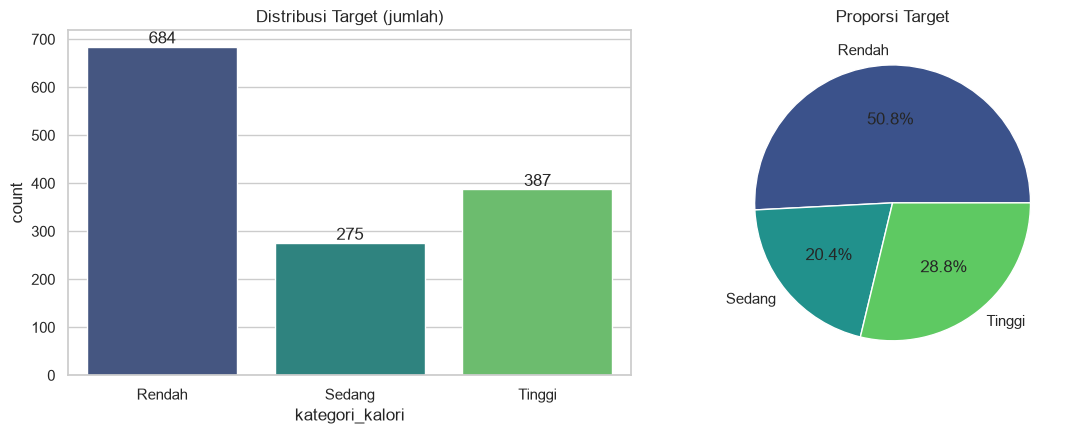

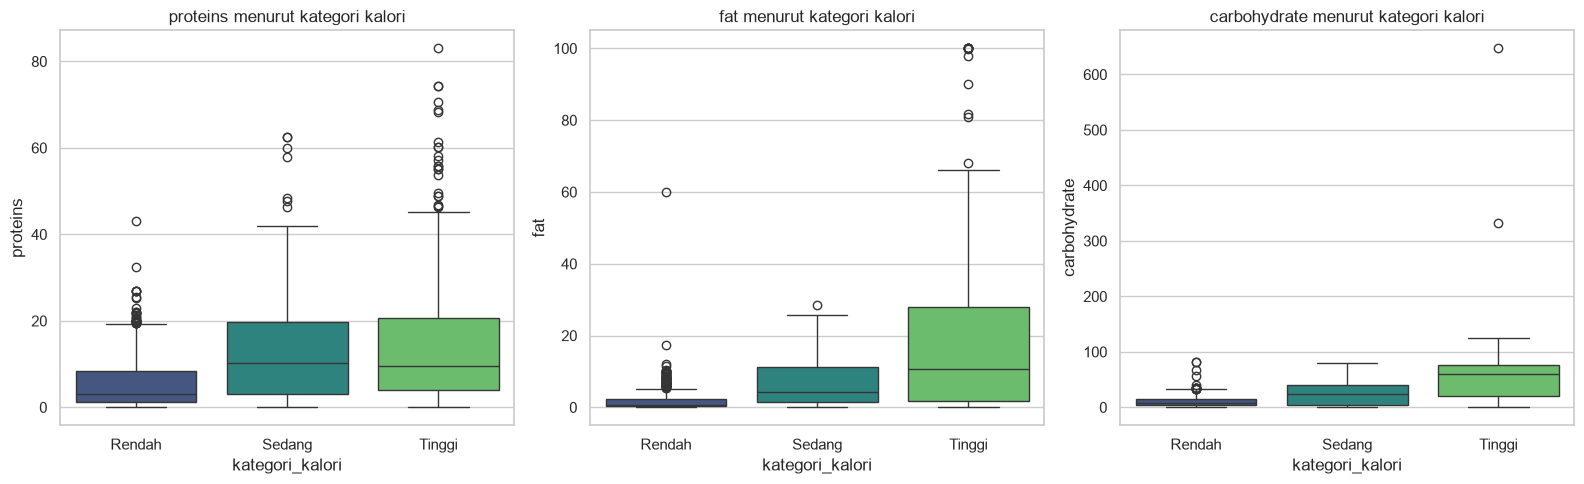

,proteins,fat,carbohydrate
kategori_kalori,,,
Rendah,5.76,1.88,10.70
Sedang,13.90,6.96,24.53
Tinggi,14.73,18.11,51.96


In [9]:
# Membuat variabel target dari kalori
def kategori_kalori(kal):
    if kal < 150: return 'Rendah'
    elif kal <= 300: return 'Sedang'
    return 'Tinggi'

ORDER = ['Rendah', 'Sedang', 'Tinggi']
df['kategori_kalori'] = df['calories'].map(kategori_kalori)

# --- Visualisasi target ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=df, x='kategori_kalori', order=ORDER, palette='viridis', ax=axes[0])
axes[0].set_title('Distribusi Target (jumlah)')
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha='center', va='bottom')
df['kategori_kalori'].value_counts(normalize=True).reindex(ORDER).plot(
    kind='pie', autopct='%1.1f%%', ax=axes[1], colors=sns.color_palette('viridis', 3))
axes[1].set_ylabel('')
axes[1].set_title('Proporsi Target')
plt.tight_layout()
plt.show()

# --- Visualisasi fitur terhadap target ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, kol in zip(axes, ['proteins', 'fat', 'carbohydrate']):
    sns.boxplot(data=df, x='kategori_kalori', y=kol, order=ORDER, palette='viridis', ax=ax)
    ax.set_title(f'{kol} menurut kategori kalori')
plt.tight_layout()
plt.show()

# Rata-rata makro per kategori
display(df.groupby('kategori_kalori')[['proteins', 'fat', 'carbohydrate']].mean().reindex(ORDER).round(2))

**Penjelasan temuan**
- **Target tidak seimbang:** *Rendah* paling banyak (±51%), *Tinggi* (±29%), dan *Sedang* paling sedikit (±20%). Rasio kelas terbesar : terkecil ≈ 2,5 : 1, jadi perlu penanganan *imbalance* saat preprocessing.
- **Lemak dan karbohidrat** adalah pembeda paling jelas: rata-rata lemak naik dari ±1,9 g (Rendah) ke ±18 g (Tinggi), dan karbohidrat dari ±10,7 g ke ±52 g. Sebarannya lebar dan banyak outlier.
- **Protein** lebih tumpang tindih, terutama antara Sedang dan Tinggi (rata-rata ±13,9 vs ±14,7 g), jadi pembedanya lebih lemah.

## 8. Analisis Korelasi antar Fitur dan Target

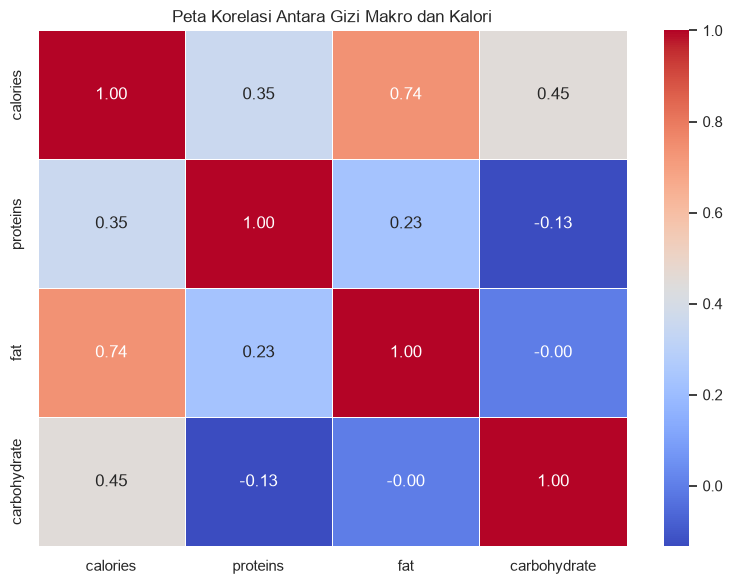

Korelasi Spearman fitur vs target ordinal:
proteins        0.336
fat             0.533
carbohydrate    0.498
dtype: float64

Korelasi kalori vs (4*protein + 9*lemak + 4*karbohidrat): 0.886
Korelasi lemak vs karbohidrat: -0.004
Korelasi protein vs karbohidrat: -0.133


In [10]:
# Membuat heatmap korelasi antara kalori, protein, lemak, dan karbohidrat
plt.figure(figsize=(8, 6))
korelasi = df[kolom_numerik].corr()

sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Peta Korelasi Antara Gizi Makro dan Kalori')
plt.tight_layout()
plt.show()

# Korelasi (Spearman) fitur dengan target ordinal (Rendah=0, Sedang=1, Tinggi=2)
target_ord = df['kategori_kalori'].map({'Rendah': 0, 'Sedang': 1, 'Tinggi': 2})
print("Korelasi Spearman fitur vs target ordinal:")
print(df[['proteins', 'fat', 'carbohydrate']].corrwith(target_ord, method='spearman').round(3))

# Konsistensi rumus energi
est = 4 * df['proteins'] + 9 * df['fat'] + 4 * df['carbohydrate']
print("\nKorelasi kalori vs (4*protein + 9*lemak + 4*karbohidrat):", round(df['calories'].corr(est), 3))
print("Korelasi lemak vs karbohidrat:", round(df['fat'].corr(df['carbohydrate']), 3))
print("Korelasi protein vs karbohidrat:", round(df['proteins'].corr(df['carbohydrate']), 3))

**Insight dari korelasi (min. 3)**

1. **Lemak adalah prediktor terkuat** nilai kalori (r ≈ 0,74), lebih kuat daripada karbohidrat (≈ 0,45) dan protein (≈ 0,35). Terhadap kategori target, lemak (ρ ≈ 0,53) dan karbohidrat (ρ ≈ 0,50) sama-sama kuat. **Keputusan modeling:** lemak dan karbohidrat menjadi fitur utama, protein tetap dipakai sebagai pelengkap.
2. **Antar fitur makro korelasinya hampir nol** (lemak–karbohidrat ≈ 0, protein–karbohidrat sedikit negatif). Tidak ada multikolinearitas serius, jadi ketiganya **tidak redundan** dan aman dipakai bersama.
3. **Kalori hampir sepenuhnya ditentukan oleh rumus 4P + 9L + 4K** (korelasi tinggi), tetapi korelasi tidak sempurna karena ada baris yang salah catat. **Keputusan cleaning:** baris yang kalorinya sangat menyimpang dari rumus ini dianggap kesalahan data dan dibuang.
4. Karena target dibuat dari `calories`, kolom `calories` **tidak boleh dijadikan fitur** (*data leakage*). **Keputusan modeling:** `calories` dikeluarkan dari fitur.

# C. Audit Kualitas Data

## 9. Missing Value, Outlier, dan Duplikat per Kolom

,Kolom,Missing,% Missing,Duplikat nilai,Outlier (IQR),% Outlier,Batas bawah,Batas atas,Jumlah nol
0,id,0,0.0,0,-,-,-,-,-
1,calories,0,0.0,874,13.0,0.97,-313.12,721.88,1.0
2,proteins,0,0.0,1034,64.0,4.75,-18.0,34.8,22.0
3,fat,0,0.0,1067,162.0,12.04,-11.16,19.94,26.0
4,carbohydrate,0,0.0,802,17.0,1.26,-45.05,87.15,104.0
5,name,0,0.0,0,-,-,-,-,-
6,image,0,0.0,39,-,-,-,-,-


Duplikat baris penuh                          : 0
Duplikat baris (tanpa id)                     : 0
Duplikat nama (case-insensitive, tanpa spasi) : 3


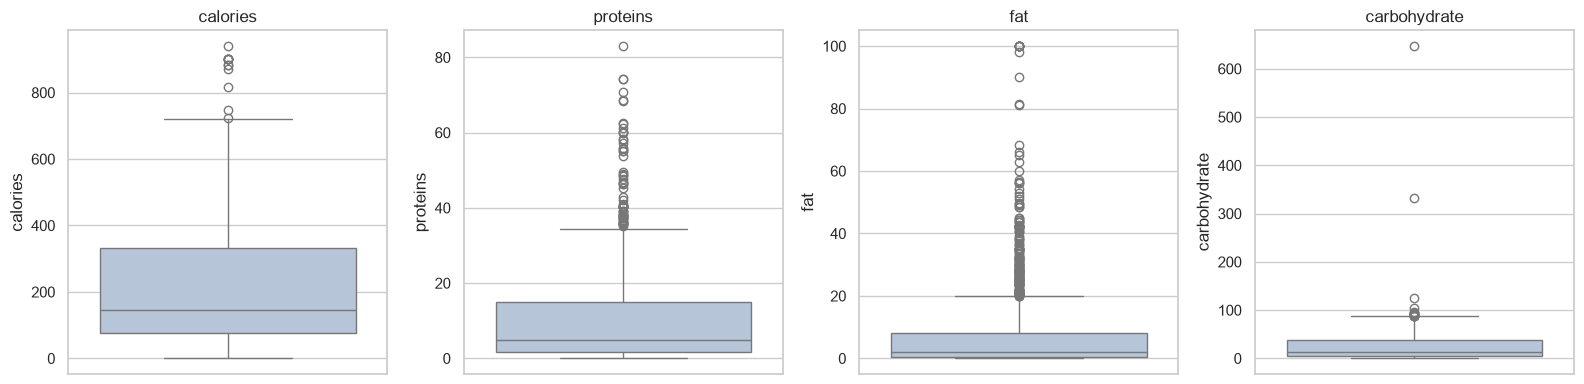

In [11]:
# Audit per kolom pada data MENTAH (sebelum cleaning)
def hitung_outlier_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((s < batas_bawah) | (s > batas_atas)).sum()), batas_bawah, batas_atas

audit = []
for kol in df.drop(columns='kategori_kalori').columns:
    baris = {'Kolom': kol,
             'Missing': int(df[kol].isnull().sum()),
             '% Missing': round(df[kol].isnull().mean() * 100, 2),
             'Duplikat nilai': int(df[kol].duplicated().sum())}
    if kol in kolom_numerik:
        n_out, bb, ba = hitung_outlier_iqr(df[kol])
        baris.update({'Outlier (IQR)': n_out, '% Outlier': round(n_out / len(df) * 100, 2),
                      'Batas bawah': round(bb, 2), 'Batas atas': round(ba, 2),
                      'Jumlah nol': int((df[kol] == 0).sum())})
    audit.append(baris)
audit_df = pd.DataFrame(audit).fillna('-')
display(audit_df)

# Duplikat tingkat baris
print("Duplikat baris penuh                          :", df.drop(columns='kategori_kalori').duplicated().sum())
print("Duplikat baris (tanpa id)                     :", df.drop(columns=['id', 'kategori_kalori']).duplicated().sum())
print("Duplikat nama (case-insensitive, tanpa spasi) :", df['name'].str.strip().str.lower().duplicated().sum())

# Boxplot untuk melihat outlier
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, kol in zip(axes, kolom_numerik):
    sns.boxplot(y=df[kol], ax=ax, color='lightsteelblue')
    ax.set_title(kol)
plt.tight_layout()
plt.show()

**Analisis audit**
- **Missing value: 0** pada semua kolom, jadi tidak perlu imputasi.
- **Duplikat:** tidak ada baris duplikat penuh, tetapi ada 3 nama yang duplikat bila huruf besar/kecil diabaikan (*Beras Parboiled*, *Bika Ambon*, *Terasi Merah*). `image` berulang pada 39 baris karena beberapa makanan memakai gambar yang sama (tidak bermasalah, kolom tidak dipakai).
- **Outlier IQR cukup banyak**, terutama pada `fat` (±12%). Namun sebagian besar adalah **outlier alami** (minyak, lemak babi, kacang, gorengan), yaitu makanan yang memang berlemak tinggi, jadi **tidak dibuang**. Hanya outlier yang **mustahil secara fisik** (total makro > 100 g atau kalori jauh dari rumus energi) yang dibuang.

# D. Cleaning

## 10. Strategi Penanganan Masalah Kualitas Data

| Masalah | Strategi | Alasan |
|---|---|---|
| Spasi berlebih pada nama | `strip()` | Tidak mengubah arti, hanya merapikan |
| Nama duplikat (beda huruf besar/kecil) | Hapus duplikat, simpan entri pertama | Entri sama, menghindari data bocor antar train/test |
| Total makro > 100 g | **Drop** baris | Mustahil secara fisik (per 100 g), tidak ada cara memperbaiki dengan benar |
| Kalori sangat menyimpang dari 4P+9L+4K | **Drop** baris | Label (target) menjadi salah / noisy |
| Outlier alami (lemak/karbo tinggi) | **Dipertahankan** | Nilai nyata dan informatif; ditangani dengan *RobustScaler* |
| Nilai nol | **Dipertahankan** | Nol adalah nilai valid, bukan missing |
| Missing value | Tidak ada | Tidak perlu imputasi |

In [12]:
df_awal = df.copy()                     # simpan kondisi sebelum cleaning
df_clean = df.copy()
log = []

# 1) Rapikan spasi pada nama
df_clean['name'] = df_clean['name'].str.strip()

# 2) Hapus duplikat nama (abaikan huruf besar/kecil), simpan entri pertama
n0 = len(df_clean)
df_clean = df_clean[~df_clean['name'].str.lower().duplicated(keep='first')]
log.append(('Hapus nama duplikat', n0 - len(df_clean)))

# 3) Hapus baris dengan total makro > 100 g (tidak mungkin per 100 g)
n0 = len(df_clean)
tm = df_clean['proteins'] + df_clean['fat'] + df_clean['carbohydrate']
df_clean = df_clean[tm <= 100]
log.append(('Hapus total makro > 100 g', n0 - len(df_clean)))

# 4) Hapus baris yang kalorinya sangat menyimpang dari rumus energi
n0 = len(df_clean)
est = 4 * df_clean['proteins'] + 9 * df_clean['fat'] + 4 * df_clean['carbohydrate']
rel = (est - df_clean['calories']).abs() / est.clip(lower=1)
ab = (est - df_clean['calories']).abs()
df_clean = df_clean[~((rel > 0.5) & (ab > 20))]
log.append(('Hapus kalori tidak konsisten dengan makro', n0 - len(df_clean)))

df_clean = df_clean.reset_index(drop=True)
print(pd.DataFrame(log, columns=['Langkah cleaning', 'Baris dibuang']).to_string(index=False))
print(f"\nTotal baris dibuang: {len(df_awal) - len(df_clean)} "
      f"({(len(df_awal) - len(df_clean)) / len(df_awal) * 100:.1f}% dari data)")

                         Langkah cleaning  Baris dibuang
                      Hapus nama duplikat              3
                Hapus total makro > 100 g             11
Hapus kalori tidak konsisten dengan makro             27

Total baris dibuang: 41 (3.0% dari data)


## 11. Kondisi Sebelum vs Sesudah Dibersihkan

,Sebelum,Sesudah
Jumlah baris,1346.000,1305.000
Missing value,0.000,0.000
Nama duplikat,3.000,0.000
Nama berspasi berlebih,83.000,0.000
Total makro > 100 g,11.000,0.000
Maks. karbohidrat,647.000,95.300
Rata-rata kalori,203.220,200.630
Korelasi kalori vs 4P+9L+4K,0.886,0.993


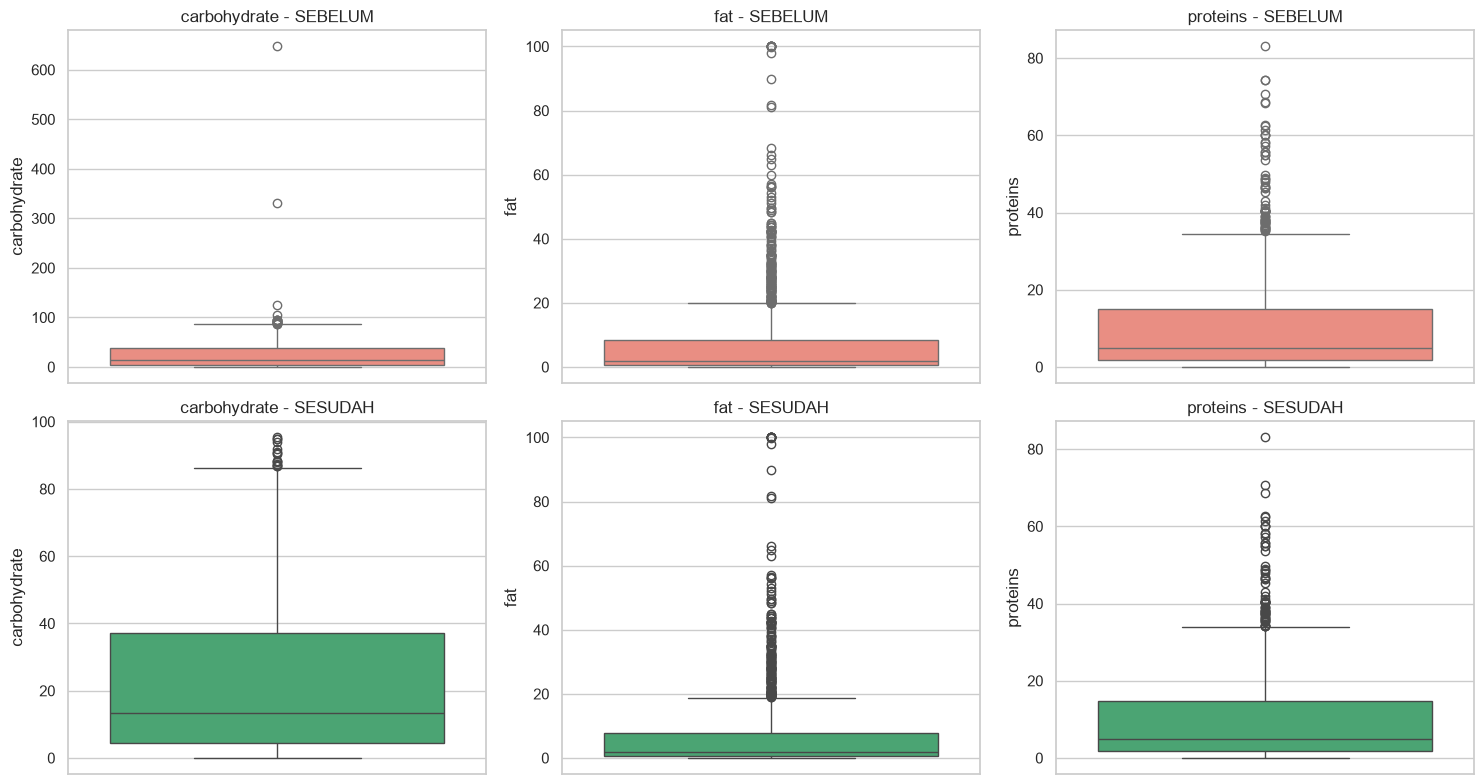

Distribusi target sebelum vs sesudah (%):


,Sebelum,Sesudah
kategori_kalori,,
Rendah,50.8,51.3
Sedang,20.4,20.4
Tinggi,28.8,28.4


In [13]:
def ringkas(d, label):
    tm = d['proteins'] + d['fat'] + d['carbohydrate']
    e = 4 * d['proteins'] + 9 * d['fat'] + 4 * d['carbohydrate']
    return pd.Series({
        'Jumlah baris': len(d),
        'Missing value': int(d[kolom_numerik].isnull().sum().sum()),
        'Nama duplikat': int(d['name'].str.strip().str.lower().duplicated().sum()),
        'Nama berspasi berlebih': int((d['name'] != d['name'].str.strip()).sum()),
        'Total makro > 100 g': int((tm > 100).sum()),
        'Maks. karbohidrat': d['carbohydrate'].max(),
        'Rata-rata kalori': round(d['calories'].mean(), 2),
        'Korelasi kalori vs 4P+9L+4K': round(d['calories'].corr(e), 3),
    }, name=label)

banding = pd.concat([ringkas(df_awal, 'Sebelum'), ringkas(df_clean, 'Sesudah')], axis=1)
display(banding)

# Visual sebelum vs sesudah
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, kol in enumerate(['carbohydrate', 'fat', 'proteins']):
    sns.boxplot(y=df_awal[kol], ax=axes[0, j], color='salmon');      axes[0, j].set_title(f'{kol} - SEBELUM')
    sns.boxplot(y=df_clean[kol], ax=axes[1, j], color='mediumseagreen'); axes[1, j].set_title(f'{kol} - SESUDAH')
plt.tight_layout()
plt.show()

print("Distribusi target sebelum vs sesudah (%):")
display(pd.concat([df_awal['kategori_kalori'].value_counts(normalize=True).reindex(ORDER) * 100,
                   df_clean['kategori_kalori'].value_counts(normalize=True).reindex(ORDER) * 100],
                  axis=1, keys=['Sebelum', 'Sesudah']).round(1))

**Hasil cleaning:** baris tidak masuk akal dan duplikat sudah dibuang, korelasi kalori terhadap rumus energi **naik** (data lebih konsisten), dan nilai maksimum karbohidrat kini wajar (≤ 100 g). Proporsi target nyaris tidak berubah, sehingga pembersihan **tidak menimbulkan bias** pada kelas.

# E. Preprocessing

## 12. Encoding, Scaling, dan Penanganan Data Imbalance

Urutan dibuat **split dulu, baru fit** transformer agar tidak terjadi *data leakage*. Karena itu, di sini fitur baru dibuat lebih dulu, lalu train/test dibagi pada No. 13, dan encoding, scaling, serta oversampling dijalankan **setelah split** (sel di bawah No. 13).

| Langkah | Metode | Alasan |
|---|---|---|
| Fitur baru | `metode_olah`, `kelompok_pangan` dari nama | Nama makanan memuat informasi yang tidak ada di kolom gizi (mis. "goreng" menambah lemak) |
| Encoding fitur kategorikal | **One-Hot Encoding** | Kategori **nominal** (tanpa urutan), jadi ordinal encoding akan menyesatkan |
| Encoding target | **Ordinal** (Rendah=0, Sedang=1, Tinggi=2) | Kategori kalori memang berurutan |
| Scaling fitur numerik | **RobustScaler** | Data sangat *skewed* dan banyak outlier alami; RobustScaler memakai median & IQR sehingga tahan outlier |
| Data imbalance | **Random Oversampling pada data latih saja** | Rasio ±2,5 : 1 tergolong sedang, jadi cukup menggandakan kelas minoritas; tidak menyentuh data uji agar evaluasi tetap jujur. SMOTE kurang cocok karena fitur campuran numerik + one-hot |

In [14]:
# Fitur baru dari nama makanan (fungsi sudah dibuat di bagian 5)
df_clean['metode_olah'] = df_clean['name'].map(metode_olah)
df_clean['kelompok_pangan'] = df_clean['name'].map(kelompok_pangan)

# Pemetaan target ordinal
PETA_TARGET = {'Rendah': 0, 'Sedang': 1, 'Tinggi': 2}
y = df_clean['kategori_kalori'].map(PETA_TARGET)

# Kandidat fitur: calories, id, name, image TIDAK dimasukkan (alasan pada bagian 14)
fitur_num = ['proteins', 'fat', 'carbohydrate']
fitur_kat = ['metode_olah', 'kelompok_pangan']
X = df_clean[fitur_num + fitur_kat]

print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)
display(X.head())

Bentuk X: (1305, 5) | Bentuk y: (1305,)


,proteins,fat,carbohydrate,metode_olah,kelompok_pangan
0,9.2,28.4,0.0,lainnya,daging_unggas
1,23.7,37.0,21.3,lainnya,daging_unggas
2,0.0,0.2,0.0,lainnya,lainnya
3,1.1,0.4,10.8,segar_mentah,lainnya
4,4.4,0.5,3.8,segar_mentah,lainnya


## 13. Splitting Dataset Train / Test

In [15]:
# Split 80% train - 20% test, stratify agar proporsi kelas terjaga
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Data latih : {X_train.shape[0]} baris ({X_train.shape[0] / len(X) * 100:.0f}%)")
print(f"Data uji   : {X_test.shape[0]} baris ({X_test.shape[0] / len(X) * 100:.0f}%)")
print("\nProporsi kelas (%):")
display(pd.concat([y.value_counts(normalize=True).sort_index() * 100,
                   y_train.value_counts(normalize=True).sort_index() * 100,
                   y_test.value_counts(normalize=True).sort_index() * 100],
                  axis=1, keys=['Keseluruhan', 'Train', 'Test']).round(1))

Data latih : 1044 baris (80%)
Data uji   : 261 baris (20%)

Proporsi kelas (%):


,Keseluruhan,Train,Test
kategori_kalori,,,
0,51.3,51.2,51.3
1,20.4,20.4,20.3
2,28.4,28.4,28.4


Parameter `stratify=y` memastikan proporsi Rendah/Sedang/Tinggi di data latih dan uji sama dengan data aslinya. `random_state` dikunci agar hasil dapat direproduksi.

## 12 (lanjutan). Menjalankan Encoding, Scaling, dan Oversampling (setelah split)

Jumlah fitur setelah encoding: 20

Distribusi kelas data latih SEBELUM oversampling:
kategori_kalori
Rendah    535
Sedang    213
Tinggi    296
Name: count, dtype: int64

Distribusi kelas data latih SESUDAH oversampling:
Rendah    535
Sedang    535
Tinggi    535
Name: count, dtype: int64


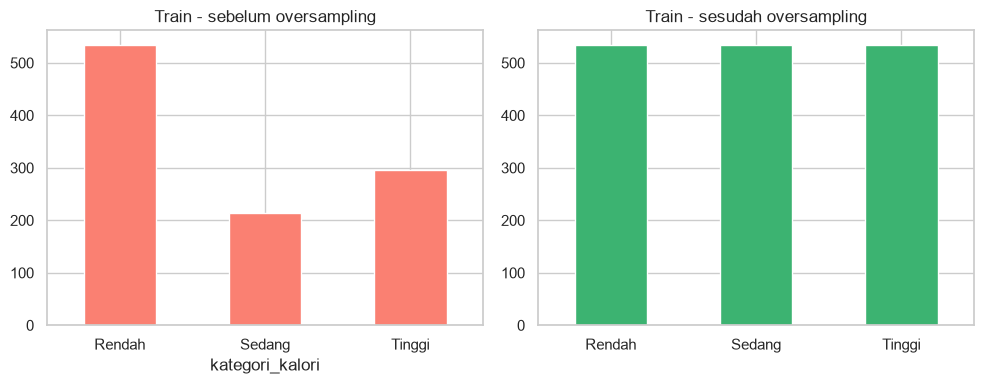

,proteins,fat,carbohydrate,metode_olah_bakar,metode_olah_goreng,metode_olah_kering,metode_olah_lainnya,metode_olah_masakan,metode_olah_rebus_kukus,metode_olah_segar_mentah,kelompok_pangan_buah,kelompok_pangan_daging_unggas,kelompok_pangan_ikan_seafood,kelompok_pangan_jajanan_olahan,kelompok_pangan_kacang_olahannya,kelompok_pangan_lainnya,kelompok_pangan_minyak_lemak,kelompok_pangan_sayur_daun,kelompok_pangan_telur_susu,kelompok_pangan_umbi_serealia
495,1.251969,3.128205,-0.124711,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
193,0.488189,0.166667,1.833718,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
28,-0.070866,0.076923,0.041570,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
266,0.015748,-0.089744,0.241724,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1226,-0.291339,-0.192308,2.301771,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [16]:
# --- Encoding + Scaling (fit hanya pada data latih) ---
preprocessor = ColumnTransformer([
    ('num', RobustScaler(), fitur_num),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), fitur_kat),
])
Xtr_arr = preprocessor.fit_transform(X_train)
Xte_arr = preprocessor.transform(X_test)

nama_fitur = [n.split('__')[1] for n in preprocessor.get_feature_names_out()]
Xtr = pd.DataFrame(Xtr_arr, columns=nama_fitur, index=X_train.index)
Xte = pd.DataFrame(Xte_arr, columns=nama_fitur, index=X_test.index)
print("Jumlah fitur setelah encoding:", Xtr.shape[1])

# --- Penanganan imbalance: random oversampling HANYA pada data latih ---
print("\nDistribusi kelas data latih SEBELUM oversampling:")
print(y_train.value_counts().sort_index().rename(index={0: 'Rendah', 1: 'Sedang', 2: 'Tinggi'}))

n_max = y_train.value_counts().max()
bagian = []
for kelas in sorted(y_train.unique()):
    idx = y_train[y_train == kelas].index
    bagian.append(resample(Xtr.loc[idx], replace=True, n_samples=n_max, random_state=RANDOM_STATE))
Xtr_bal = pd.concat(bagian)
ytr_bal = pd.Series(np.repeat(sorted(y_train.unique()), n_max), index=range(len(Xtr_bal)))
Xtr_bal = Xtr_bal.reset_index(drop=True)

print("\nDistribusi kelas data latih SESUDAH oversampling:")
print(ytr_bal.value_counts().sort_index().rename(index={0: 'Rendah', 1: 'Sedang', 2: 'Tinggi'}))

# Visual sebelum vs sesudah
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.map({0: 'Rendah', 1: 'Sedang', 2: 'Tinggi'}).value_counts().reindex(ORDER).plot(
    kind='bar', ax=axes[0], color='salmon', rot=0)
axes[0].set_title('Train - sebelum oversampling')
ytr_bal.map({0: 'Rendah', 1: 'Sedang', 2: 'Tinggi'}).value_counts().reindex(ORDER).plot(
    kind='bar', ax=axes[1], color='mediumseagreen', rot=0)
axes[1].set_title('Train - sesudah oversampling')
plt.tight_layout()
plt.show()

display(Xtr.head())

# F. Feature Selection

## 14. Pemilihan Fitur, Alasan, dan Bukti

### Kolom yang **dibuang**

| Kolom | Alasan dibuang |
|---|---|
| `id` | Hanya nomor urut, tidak membawa informasi gizi (bisa menyebabkan model menghafal urutan) |
| `image` | Berupa URL; tidak bermakna untuk prediksi dan tidak dianalisis |
| `name` | Teks unik per baris (kardinalitas tinggi) sehingga memicu *overfitting*; informasinya sudah diekstrak menjadi 2 fitur baru |
| `calories` | **Data leakage**: target `kategori_kalori` dibuat langsung dari kolom ini |

### Fitur yang **dibuat** dan alasannya

| Fitur baru | Cara dibuat | Alasan dibuat |
|---|---|---|
| `metode_olah` | Kata kunci pada nama (goreng, rebus/kukus, bakar, masakan, kering, segar/mentah) | Cara olah memengaruhi kalori (mis. menggoreng menambah lemak) dan tidak ada di kolom gizi |
| `kelompok_pangan` | Kata kunci pada nama (ikan, daging, buah, umbi/serealia, dll.) | Dataset tidak punya kategori pangan; kelompok pangan punya profil gizi yang khas |

Berikut **bukti** statistik untuk memilih fitur.

,Fitur,Mutual Info,F-score,p-value,RF Importance
0,carbohydrate,0.3741,375.4788,0.0000,0.3664
1,fat,0.2961,196.0619,0.0000,0.2782
2,proteins,0.1479,86.4619,0.0000,0.1753
3,metode_olah_segar_mentah,0.0482,43.7425,0.0000,0.0260
4,kelompok_pangan_sayur_daun,0.0701,53.5571,0.0000,0.0255
5,kelompok_pangan_umbi_serealia,0.0069,24.0049,0.0000,0.0161
6,metode_olah_lainnya,0.0142,8.9187,0.0001,0.0142
7,kelompok_pangan_daging_unggas,0.0192,9.4670,0.0001,0.0135
8,kelompok_pangan_ikan_seafood,0.0000,2.1622,0.1156,0.0111
9,kelompok_pangan_kacang_olahannya,0.0049,19.1096,0.0000,0.0104


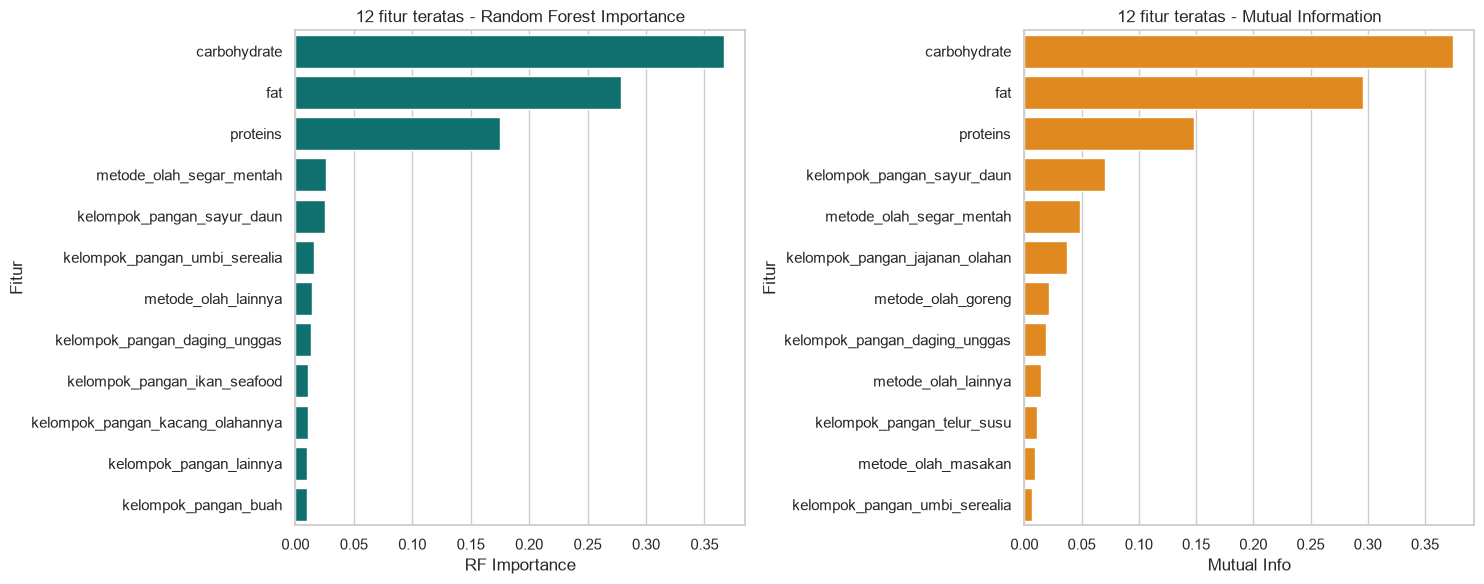

In [17]:
# Bukti 1: Mutual Information & ANOVA F-score (dihitung pada data latih asli, sebelum oversampling)
mi = mutual_info_classif(Xtr, y_train, random_state=RANDOM_STATE)
f_val, p_val = f_classif(Xtr, y_train)

# Bukti 2: Feature importance dari Random Forest
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced')
rf.fit(Xtr_bal, ytr_bal)

bukti = pd.DataFrame({'Fitur': Xtr.columns, 'Mutual Info': mi, 'F-score': f_val,
                      'p-value': p_val, 'RF Importance': rf.feature_importances_})
bukti = bukti.sort_values('RF Importance', ascending=False).reset_index(drop=True)
display(bukti.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = bukti.head(12)
sns.barplot(data=top, y='Fitur', x='RF Importance', color='teal', ax=axes[0])
axes[0].set_title('12 fitur teratas - Random Forest Importance')
sns.barplot(data=bukti.sort_values('Mutual Info', ascending=False).head(12),
            y='Fitur', x='Mutual Info', color='darkorange', ax=axes[1])
axes[1].set_title('12 fitur teratas - Mutual Information')
plt.tight_layout()
plt.show()

Rata-rata kalori per kelompok pangan:


,count,mean
kelompok_pangan,,
minyak_lemak,20,629.6
jajanan_olahan,43,345.3
telur_susu,25,279.3
kacang_olahannya,153,278.5
umbi_serealia,182,255.6
daging_unggas,126,216.0
ikan_seafood,155,188.2
lainnya,385,170.1
buah,83,94.4


Rata-rata kalori per metode olah:


,count,mean
metode_olah,,
goreng,71,360.6
kering,53,332.4
lainnya,716,219.5
bakar,8,195.1
masakan,71,165.4
segar_mentah,330,128.3
rebus_kukus,56,103.9


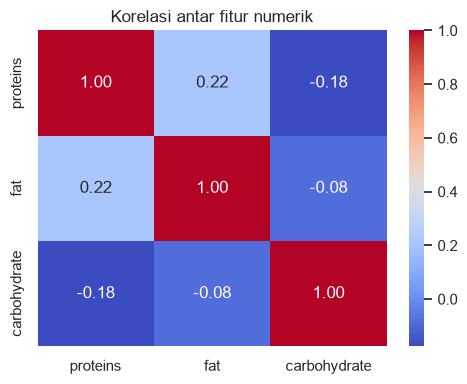

In [18]:
# Bukti 3: efek metode_olah & kelompok_pangan terhadap kalori (dasar pembuatan fitur baru)
print("Rata-rata kalori per kelompok pangan:")
display(df_clean.groupby('kelompok_pangan')['calories'].agg(['count', 'mean']).round(1).sort_values('mean', ascending=False))
print("Rata-rata kalori per metode olah:")
display(df_clean.groupby('metode_olah')['calories'].agg(['count', 'mean']).round(1).sort_values('mean', ascending=False))

# Bukti 4: Fitur numerik tidak redundan (korelasi antar fitur)
plt.figure(figsize=(5, 4))
sns.heatmap(df_clean[fitur_num].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi antar fitur numerik')
plt.tight_layout()
plt.show()

In [19]:
# Keputusan akhir: pertahankan fitur dengan kontribusi bermakna.
# Kriteria: Mutual Information > 0.01 ATAU RF Importance > 0.01
terpilih = bukti[(bukti['Mutual Info'] > 0.01) | (bukti['RF Importance'] > 0.01)]['Fitur'].tolist()
dibuang = [f for f in Xtr.columns if f not in terpilih]

print(f"Fitur terpilih ({len(terpilih)}): {terpilih}")
print(f"\nFitur dibuang ({len(dibuang)}): {dibuang}")

# Dataset akhir yang siap dipakai untuk modeling
X_train_final = Xtr_bal[terpilih]
y_train_final = ytr_bal
X_test_final = Xte[terpilih]
print("\nBentuk akhir -> X_train:", X_train_final.shape, "| X_test:", X_test_final.shape)

Fitur terpilih (15): ['carbohydrate', 'fat', 'proteins', 'metode_olah_segar_mentah', 'kelompok_pangan_sayur_daun', 'kelompok_pangan_umbi_serealia', 'metode_olah_lainnya', 'kelompok_pangan_daging_unggas', 'kelompok_pangan_ikan_seafood', 'kelompok_pangan_kacang_olahannya', 'kelompok_pangan_lainnya', 'kelompok_pangan_buah', 'metode_olah_goreng', 'kelompok_pangan_jajanan_olahan', 'kelompok_pangan_telur_susu']

Fitur dibuang (5): ['metode_olah_bakar', 'metode_olah_kering', 'metode_olah_masakan', 'metode_olah_rebus_kukus', 'kelompok_pangan_minyak_lemak']

Bentuk akhir -> X_train: (1605, 15) | X_test: (261, 15)


### Kesimpulan Feature Selection
- **`carbohydrate`, `fat`, `proteins`** dipertahankan: ketiganya memiliki nilai *Mutual Information*, *F-score*, dan *importance* tertinggi, serta saling berkorelasi lemah sehingga tidak redundan.
- **Fitur turunan nama** (`metode_olah`, `kelompok_pangan`) dipertahankan hanya untuk kategori yang kontribusinya bermakna (aturan: Mutual Information > 0,01 atau RF importance > 0,01). Lima kategori dibuang (`metode_olah_bakar`, `_kering`, `_masakan`, `_rebus_kukus`, dan `kelompok_pangan_minyak_lemak`) karena kontribusinya sangat kecil atau jumlahnya terlalu sedikit (mis. kelompok minyak/lemak hanya ±20 baris, dan sifatnya sudah tertangkap oleh fitur `fat`). Hasilnya model lebih sederhana dan risiko overfitting turun.
- Nilai *importance* tertinggi justru **`carbohydrate`**, lalu `fat` dan `proteins`; ketiganya jauh di atas fitur turunan nama.
- `id`, `image`, `name`, dan `calories` dibuang karena alasan di tabel di atas (tidak informatif, kardinalitas tinggi, dan *data leakage*).
- **Data siap** untuk tahap modeling: `X_train_final`, `y_train_final`, `X_test_final`, `y_test`.